In [1]:
import json
import os

os.environ["SPS_HOME"] = "/Users/z5114326/Documents/GitHub/python-fsps/src/fsps/libfsps"

import fsps
import gc_utils
import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.cosmology import LambdaCDM, default_cosmology
from scipy.interpolate import interp1d

# plt.rc("font", family="Nimbus Roman")
plt.rc("font", family="Nimbus Roman No9 L")

SMALL_SIZE = 7
MEDIUM_SIZE = 7
BIGGER_SIZE = 7

plt.rc("font", size=SMALL_SIZE)  # controls default text sizes
plt.rc("axes", titlesize=SMALL_SIZE)  # fontsize of the axes title
plt.rc("axes", labelsize=MEDIUM_SIZE)  # fontsize of the x and y labels
plt.rc("xtick", labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc("ytick", labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc("legend", fontsize=SMALL_SIZE)  # legend fontsize
plt.rc("figure", titlesize=BIGGER_SIZE)  # fontsize of the figure title

In [2]:
sim_lst = ["m12b", "m12c", "m12f", "m12i", "m12m"]
sim_dir = "/Users/z5114326/Documents/simulations/"

# bands = ["jwst_f150w", "jwst_f444w"]
# bands = ["jwst_f115w"]

snap = 600
min_mass = 1e4

scmap = plt.get_cmap("tab10")
colors = [scmap(i) for i in np.linspace(0, 1, len(sim_lst))]
sim_colors = {sim: colors[i] for i, sim in enumerate(sim_lst)}

In [3]:
sp = fsps.StellarPopulation(imf_type=2, zcontinuous=1, compute_vega_mags=False)

sp.params["add_dust_emission"] = False
sp.params["add_neb_continuum"] = False
sp.params["add_neb_emission"] = False
sp.params["add_agb_dust_model"] = False
sp.params["dust1"] = 0.0
sp.params["dust2"] = 0.0
sp.params["fcstar"] = 0.0
sp.params["agb_dust"] = 0.0
sp.params["tpagb_norm_type"] = 0

In [4]:
# jwst_filters = fsps.find_filter("jwst")
bands = fsps.find_filter("jwst")

In [5]:
public_snapshot_file = sim_dir + "snapshot_times_public.txt"
pub_data = pd.read_table(public_snapshot_file, comment="#", header=None, sep=r"\s+")
pub_data.columns = [
    "index",
    "scale_factor",
    "redshift",
    "time_Gyr",
    "lookback_time_Gyr",
    "time_width_Myr",
]
timez0 = float(pub_data[pub_data["index"] == snap]["time_Gyr"].values[0])
pub_snaps = np.array(pub_data["index"])

all_data_fil = sim_dir + "/" + "m12i" + "/" + "m12i" + "_res7100/" + "snapshot_times.txt"
all_data = pd.read_table(all_data_fil, comment="#", header=None, sep=r"\s+")
all_data.columns = [
    "index",
    "scale_factor",
    "redshift",
    "time_Gyr",
    "lookback_time_Gyr",
    "time_width_Myr",
]
all_times = np.array(all_data["time_Gyr"])
all_snaps = np.array(all_data["index"])

snap_times = {
    gc_utils.snapshot_name(s): float(pub_data.loc[pub_data["index"] == s, "time_Gyr"].values[0])
    for s in pub_snaps
}

In [6]:
cosmo = LambdaCDM(H0=70.2, Om0=0.272, Ode0=0.728, Ob0=0.0455)
# cosmo = default_cosmology.get()

In [7]:
to_path = "../data/sim_data/turn_offs_lbt.json"
with open(to_path, "r", encoding="utf-8") as f:
    to_dict = json.load(f)

In [8]:
sim_dict = {}

# ------------------------------------------------
# precompute snapshot times once
# ------------------------------------------------
snap_times = {
    gc_utils.snapshot_name(s): float(pub_data.loc[pub_data["index"] == s, "time_Gyr"].values[0])
    for s in pub_snaps
}

timez0 = snap_times[gc_utils.snapshot_name(snap)]

for sim in sim_lst:
    ghost_file = f"{sim_dir}{sim}/{sim}_ghosts.hdf5"
    sim_dict[sim] = {}

    with h5py.File(ghost_file, "r") as ghost_data:
        for it_id, it_grp in ghost_data.items():
            src = it_grp["source"]

            # ---------------------------
            # read once
            # ---------------------------
            grpid = src["grpid"][()]
            amsk = grpid == 0

            logm_tfor = src["logm_tfor"][()]
            logm_tz0 = src["logm_tz0"][()]

            m_tfo = 10.0**logm_tfor
            m_tfo_ev = 0.55 * m_tfo  # stellar-evolution corrected mass

            m_tz0 = np.zeros_like(logm_tz0, dtype=float)
            msk = logm_tz0 != -1
            m_tz0[msk] = 10.0 ** logm_tz0[msk]

            tfor = src["tfor"][()]
            tdis = src["tdis"][()]
            tacc = src["tacc"][()]
            feh = src["feh"][()]
            gcids = src["gcid"][()]

            tdis = np.where(tdis == -1, np.inf, tdis)

            rz0 = np.linalg.norm(src["pxyz_snap600"][()], axis=1)

            # ---------------------------
            # vectorized ages
            # ---------------------------
            age = timez0 - tfor
            age_p = np.where(np.isfinite(tdis), tdis - tfor, age)

            t_tz0 = src["torb_600"][()]
            s_tz0 = src["s_flag"][()].astype(bool)
            sa_flag = src["sa_flag"][()].astype(bool)

            # ---------------------------
            # snapshot mass table
            #   + tfor (m_tfo_ev)
            #   + tdis (0)
            # ---------------------------
            n_gc = len(gcids)
            n_snap = len(pub_snaps)

            mass_arr = np.full((n_gc, n_snap + 2), np.nan)
            time_arr = np.full((n_gc, n_snap + 2), np.nan)

            # ---- formation point ----
            mass_arr[:, 0] = m_tfo_ev
            time_arr[:, 0] = tfor

            # ---- simulation snapshots ----
            for j, (snap_id, time) in enumerate(snap_times.items(), start=1):
                snp = it_grp["snapshots"][snap_id]
                snp_gcids = snp["gcid"][()]
                snp_mass = 10.0 ** snp["logm"][()]

                common, idx_snp, idx_src = np.intersect1d(snp_gcids, gcids, return_indices=True)

                mass_arr[idx_src, j] = snp_mass[idx_snp]
                time_arr[idx_src, j] = time

                # ---- disruption point (only if disrupted) ----
                has_disrupted = np.isfinite(tdis)

                mass_arr[has_disrupted, -1] = 0.0
                time_arr[has_disrupted, -1] = tdis[has_disrupted]

            # ---------------------------
            # final mass cut
            # ---------------------------
            m_tfo_msk = m_tfo >= min_mass

            sim_dict[sim][it_id] = {
                "gcid": gcids[m_tfo_msk],
                "feh": feh[m_tfo_msk],
                "tfor": tfor[m_tfo_msk],
                "tdis": tdis[m_tfo_msk],
                "tacc": tacc[m_tfo_msk],
                "age": age[m_tfo_msk],
                "age_p": age_p[m_tfo_msk],
                "rz0": rz0[m_tfo_msk],
                "t_tz0": t_tz0[m_tfo_msk],
                "s_tz0": s_tz0[m_tfo_msk],
                "sa_flag": sa_flag[m_tfo_msk],
                "acc": amsk[m_tfo_msk],
                # ---- masses ----
                "m_tfo": m_tfo[m_tfo_msk],
                "m_tfo_ev": m_tfo_ev[m_tfo_msk],
                "m_tz0": m_tz0[m_tfo_msk],
                # ---- time-resolved mass history ----
                "m_snp": mass_arr[m_tfo_msk],
                "t_snp": time_arr[m_tfo_msk],
            }

In [9]:
# def build_mass_interpolators(dat):
#     interps = []

#     for m, t in zip(dat["m_snp"], dat["t_snp"]):
#         msk = np.isfinite(m) & (m > 0)
#         if np.sum(msk) < 2:
#             interps.append(None)
#             continue

#         order = np.argsort(t[msk])
#         ts = t[msk][order]
#         ms = m[msk][order]

#         interps.append(interp1d(ts, ms, kind="linear", bounds_error=False, fill_value=(ms[0], 0.0)))

#     return interps


# for sim in sim_lst:
#     for it_id in sim_dict[sim]:
#         sim_dict[sim][it_id]["mass_interp"] = build_mass_interpolators(sim_dict[sim][it_id])

In [10]:
def build_mass_interpolators(dat):
    interps = []

    for m, t in zip(dat["m_snp"], dat["t_snp"]):
        # keep the disruption point (m=0 at tdis)
        msk = np.isfinite(m)

        if np.sum(msk) < 2:
            interps.append(None)
            continue

        order = np.argsort(t[msk])

        ts = t[msk][order]
        ms = m[msk][order]

        interps.append(
            interp1d(
                ts,
                ms,
                kind="linear",
                bounds_error=False,
                fill_value=(ms[0], 0.0),
            )
        )

    return interps


for sim in sim_lst:
    for it_id in sim_dict[sim]:
        sim_dict[sim][it_id]["mass_interp"] = build_mass_interpolators(sim_dict[sim][it_id])

In [11]:
tims_dict = {sim: {"t": [], "z": []} for sim in sim_lst}
for sim in sim_lst:
    idx_to = np.argmin(np.abs(all_data["lookback_time_Gyr"] - to_dict["cnt"][sim]))
    tims_dict[sim]["t"].append(all_data["time_Gyr"][idx_to])
    tims_dict[sim]["z"].append(all_data["redshift"][idx_to])
tims_dict

{'m12b': {'t': [3.208326753], 'z': [2.104477644]},
 'm12c': {'t': [4.434278151], 'z': [1.48031497]},
 'm12f': {'t': [3.208326753], 'z': [2.104477644]},
 'm12i': {'t': [5.189943753], 'z': [1.218309641]},
 'm12m': {'t': [3.895132762], 'z': [1.715517044]}}

In [12]:
# ============================================================
# BUILD TIME-DEPENDENT GC MAGNITUDES INTO ssp_dict
# ============================================================

print("\n================ BUILDING ssp_dict ================\n")

bands_tag = "_".join(bands)
n_band = len(bands)

ssp_dict = {}

for sim in sim_lst:
    print(f"[SIM] {sim}")

    # --------------------------------------------------------
    # Collect (age, feh) pairs needed for THIS SIM
    # --------------------------------------------------------
    ages_all = []
    fehs_all = []

    for it_id, dat in sim_dict[sim].items():
        tfor = dat["tfor"]
        feh = dat["feh"]

        for t in tims_dict[sim]["t"]:
            age_t = t - tfor
            msk = age_t > 0
            if np.any(msk):
                ages_all.append(age_t[msk])
                fehs_all.append(feh[msk])

    ages_all = np.concatenate(ages_all)
    fehs_all = np.concatenate(fehs_all)

    ssp_params = np.column_stack((ages_all, fehs_all))
    unique_ssps = np.unique(ssp_params, axis=0)

    print(f"Unique SSPs needed: {len(unique_ssps)}")

    # --------------------------------------------------------
    # FSPS cache (per sim, per band system)
    # --------------------------------------------------------
    cache_dir = f"../data/ssp_caches/{sim}"
    os.makedirs(cache_dir, exist_ok=True)
    cache_path = f"{cache_dir}/jwst_obs_comp.npz"

    if os.path.exists(cache_path):
        print("  → Loading FSPS cache")
        cache = np.load(cache_path)
        ssp_mag = cache["ssp_mag"]
        ssp_mass = cache["ssp_mass"]
        cached_ssps = cache["unique_ssps"]

        if not np.array_equal(cached_ssps, unique_ssps):
            print("SSP grid mismatch — recomputing")
            recompute = True
        else:
            recompute = False
    else:
        recompute = True

    if recompute:
        print("Computing FSPS SSP grid")
        n_ssp = len(unique_ssps)

        ssp_mag = np.empty((n_ssp, n_band))
        ssp_mass = np.empty(n_ssp)

        for i, (age, feh) in enumerate(unique_ssps):
            if i % 100 == 0 or i == n_ssp - 1:
                print(f"    SSP {i + 1}/{n_ssp}")

            sp.params["logzsol"] = feh
            ssp_mag[i] = sp.get_mags(tage=age, bands=bands)
            ssp_mass[i] = sp.stellar_mass

        np.savez(
            cache_path,
            unique_ssps=unique_ssps,
            ssp_mag=ssp_mag,
            ssp_mass=ssp_mass,
        )

    # --------------------------------------------------------
    # Build fast lookup: (age, feh) -> SSP index
    # --------------------------------------------------------
    ssp_lookup = {(unique_ssps[i, 0], unique_ssps[i, 1]): i for i in range(len(unique_ssps))}

    # --------------------------------------------------------
    # Allocate output dictionary for this sim
    # --------------------------------------------------------
    # ssp_dict[sim] = {"times": np.asarray(tims_dict[sim]["t"])}
    ssp_dict[sim] = {}

    # --------------------------------------------------------
    # Compute magnitudes for each it_id
    # --------------------------------------------------------
    for it_id, dat in sim_dict[sim].items():
        print(f"    [ITER] {it_id}")

        gcids = dat["gcid"]
        tfor = dat["tfor"]
        feh = dat["feh"]
        tdis = dat["tdis"]
        tacc = dat["tacc"]
        mass_interp = dat["mass_interp"]
        insitu = dat["acc"]

        n_gc = len(gcids)

        mags = np.full((n_gc, n_band), np.nan, dtype=float)
        m_nows = np.full(n_gc, np.nan, dtype=float)

        for t in tims_dict[sim]["t"]:
            alive = (tfor <= t) & (t < tdis) & (tacc <= t)

            for i in np.where(alive)[0]:
                fmass = mass_interp[i]
                if fmass is None:
                    continue

                m_now = float(fmass(t))
                if m_now <= 0:
                    continue

                age = t - tfor[i]
                if age <= 0:
                    continue

                ssp_idx = ssp_lookup.get((age, feh[i]))
                if ssp_idx is None:
                    continue

                mags[i, :] = ssp_mag[ssp_idx] - 2.5 * np.log10(m_now / ssp_mass[ssp_idx])
                m_nows[i] = m_now

        ssp_dict[sim][it_id] = {"mags": mags, "insitu": insitu, "mass": m_nows, "tfor": tfor}

print("\n================ ssp_dict COMPLETE ================\n")


================ BUILDING ssp_dict ================

[SIM] m12b
Unique SSPs needed: 104687
  → Loading FSPS cache
    [ITER] it000
    [ITER] it001
    [ITER] it002
    [ITER] it003
    [ITER] it004
    [ITER] it005
    [ITER] it006
    [ITER] it007
    [ITER] it008
    [ITER] it009
    [ITER] it010
    [ITER] it011
    [ITER] it012
    [ITER] it013
    [ITER] it014
    [ITER] it015
    [ITER] it016
    [ITER] it017
    [ITER] it018
    [ITER] it019
    [ITER] it020
    [ITER] it021
    [ITER] it022
    [ITER] it023
    [ITER] it024
    [ITER] it025
    [ITER] it026
    [ITER] it027
    [ITER] it028
    [ITER] it029
    [ITER] it030
    [ITER] it031
    [ITER] it032
    [ITER] it033
    [ITER] it034
    [ITER] it035
    [ITER] it036
    [ITER] it037
    [ITER] it038
    [ITER] it039
    [ITER] it040
    [ITER] it041
    [ITER] it042
    [ITER] it043
    [ITER] it044
    [ITER] it045
    [ITER] it046
    [ITER] it047
    [ITER] it048
    [ITER] it049
    [ITER] it050
    [ITER] it051
 

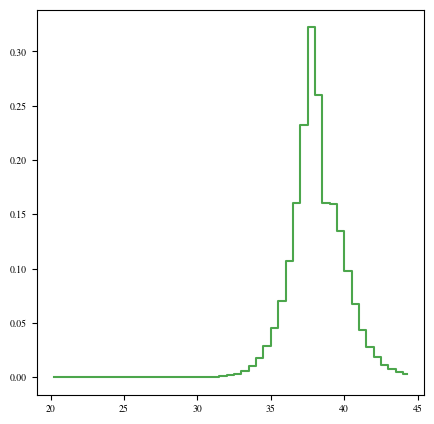

In [13]:
sim = "m12i"

fig, ax = plt.subplots(1, 1, figsize=(5, 5))

bins = np.arange(20, 45, 0.5)
bin_centres = 0.5 * (bins[:-1] + bins[1:])

hist_sim = np.zeros(len(bins) - 1)
n_realizations = 0

for it_id in ssp_dict[sim].keys():
    if it_id == "times":
        continue

    f150w_abs = ssp_dict[sim][it_id]["mags"][:, 0]
    f150w_app = f150w_abs + cosmo.distmod(tims_dict[sim]["z"]).value

    h, _ = np.histogram(f150w_app, bins=bins, density=True)
    hist_sim += h

    n_realizations += 1

hist_sim /= n_realizations

m_nows

ax.step(bin_centres, hist_sim, where="mid", color="green", lw=1.5, alpha=0.7)

In [14]:
# as according to Claeyssens et al. 2025
band_limits = {
    "jwst_f070w": 29.0,
    "jwst_f090w": 29.3,
    "jwst_f115w": 29.7,
    "jwst_f150w": 29.8,
    "jwst_f200w": 29.8,
    "jwst_f277w": 29.6,
    "jwst_f356w": 29.3,
    "jwst_f444w": 29.4,
}

redshift_bands = {
    "zrange": np.array([[0.7, 1.5], [1.5, 2.5], [2.5, 3.5], [3.5, 5.5], [5.5, 10]]),
    "filter": np.array(["jwst_f090w", "jwst_f115w", "jwst_f150w", "jwst_f200w", "jwst_f277w"]),
}


def get_filter(z, redshift_bands):
    idx = np.where((redshift_bands["zrange"][:, 0] <= z) & (z < redshift_bands["zrange"][:, 1]))[0]

    if len(idx) == 0:
        return None

    return redshift_bands["filter"][idx[0]]

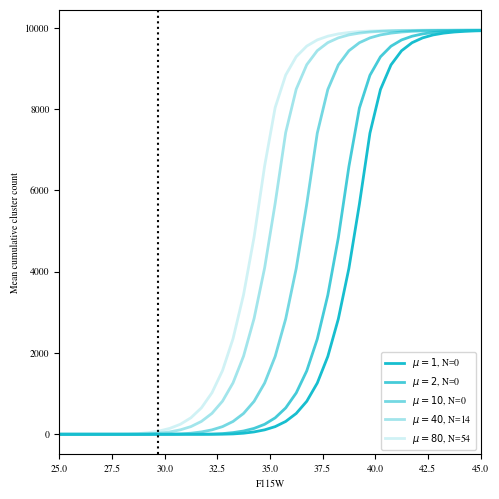

In [15]:
sim = "m12m"
band = get_filter(tims_dict[sim]["z"][0], redshift_bands)

bins = np.arange(20, 46, 0.5)
bin_centres = 0.5 * (bins[:-1] + bins[1:])

alphas = [1.0, 0.8, 0.6, 0.4, 0.2]
magnify_lst = [1, 2, 10, 40, 80]

fig, ax = plt.subplots(1, 1, figsize=(5, 5))

for alpha, magnify in zip(alphas, magnify_lst):
    cum_count_all = np.zeros(len(bin_centres))
    detectable_counts = []

    n_realizations = 0

    for it_id in ssp_dict[sim]:
        if it_id == "times":
            continue

        bidx = np.where(np.array(bands) == band)[0][0]

        m_abs = ssp_dict[sim][it_id]["mags"][:, bidx]

        m_app = m_abs + cosmo.distmod(tims_dict[sim]["z"]).value - 2.5 * np.log10(magnify)

        count_per_bin, _ = np.histogram(m_app, bins=bins)

        # cumulative number brighter than magnitude m
        cum_count = np.cumsum(count_per_bin)

        cum_count_all += cum_count

        detectable_counts.append(np.sum(m_app < band_limits[band]))

        n_realizations += 1

    cum_count_all /= n_realizations

    mean_detectable = np.mean(detectable_counts)

    ax.plot(
        bin_centres,
        cum_count_all,
        lw=2,
        color=sim_colors[sim],
        alpha=alpha,
        # label=rf"$\mu={magnify}$ ({mean_detectable:.0f})",
        label=rf"$\mu={magnify}$, N={mean_detectable:.0f}",
    )

ax.axvline(
    band_limits[band],
    ls=":",
    c="k",
    # label=f"Detection limit ({band_limits[band]:.1f})",
)

# ax.set_xlabel(f"Apparent magnitude ({band})")
ax.set_xlabel(f"{band.split('_')[-1].upper()}")
ax.set_ylabel("Mean cumulative cluster count")
ax.set_xlim(25, 45)

ax.legend()
plt.tight_layout()
plt.show()

m12b
$\mu=1$, N=0
$\mu=2$, N=0
$\mu=10$, N=0
$\mu=50$, N=7

m12c
$\mu=1$, N=0
$\mu=2$, N=0
$\mu=10$, N=0
$\mu=50$, N=19

m12f
$\mu=1$, N=0
$\mu=2$, N=0
$\mu=10$, N=1
$\mu=50$, N=13

m12i
$\mu=1$, N=0
$\mu=2$, N=0
$\mu=10$, N=2
$\mu=50$, N=37

m12m
$\mu=1$, N=0
$\mu=2$, N=0
$\mu=10$, N=0
$\mu=50$, N=23



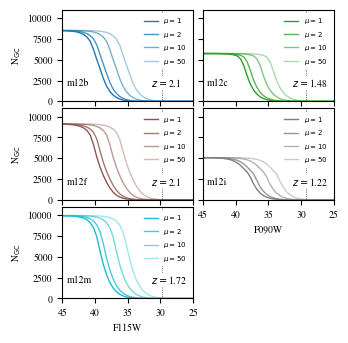

In [16]:
bins = np.arange(20, 46, 0.5)
bin_centres = 0.5 * (bins[:-1] + bins[1:])

alphas = [1.0, 0.8, 0.6, 0.4, 0.2]
# magnify_lst = [1, 2, 10, 40, 80]
magnify_lst = [1, 2, 10, 50]

fig, axs = plt.subplots(3, 2, figsize=(3.5, 3.75))
plt.subplots_adjust(hspace=0.075, wspace=0.075)

for i, ax in enumerate(axs.flatten()):
    if i > 4:
        ax.axis("off")
        continue
    sim = sim_lst[i]
    band = get_filter(tims_dict[sim]["z"][0], redshift_bands)

    print(sim)

    for alpha, magnify in zip(alphas, magnify_lst):
        cum_count_all = np.zeros(len(bin_centres))
        detectable_counts = []

        n_realizations = 0

        for it_id in ssp_dict[sim]:
            if it_id == "times":
                continue

            bidx = np.where(np.array(bands) == band)[0][0]

            m_abs = ssp_dict[sim][it_id]["mags"][:, bidx]

            m_app = m_abs + cosmo.distmod(tims_dict[sim]["z"]).value - 2.5 * np.log10(magnify)

            count_per_bin, _ = np.histogram(m_app, bins=bins)

            # cumulative number brighter than magnitude m
            cum_count = np.cumsum(count_per_bin)

            cum_count_all += cum_count

            detectable_counts.append(np.sum(m_app < band_limits[band]))

            n_realizations += 1

        cum_count_all /= n_realizations

        mean_detectable = np.mean(detectable_counts)

        ax.plot(
            bin_centres,
            cum_count_all,
            lw=1,
            color=sim_colors[sim],
            alpha=alpha,
            # label=rf"$\mu={magnify}$, N={mean_detectable:.0f}",
            label=rf"$\mu={magnify}$",
        )

        print(rf"$\mu={magnify}$, N={mean_detectable:.0f}")

    ax.axvline(band_limits[band], ls=":", c="k", lw=0.5)

    # ax.legend(fontsize=3, loc="upper left")
    ax.legend(
        fontsize=5,
        loc="upper right",
        frameon=True,
        facecolor="white",
        edgecolor="none",
        framealpha=1.0,
    )

    ax.text(
        0.03,
        0.17,
        sim,
        transform=ax.transAxes,
        # bbox=dict(facecolor="white", edgecolor="none", boxstyle="round,pad=0.3"),
        # fontsize=5,
    )

    z_txt = r"$z = $" + str(np.round(tims_dict[sim]["z"][0], 2))
    ax.text(
        0.68,
        0.16,
        z_txt,
        transform=ax.transAxes,
        bbox=dict(facecolor="white", edgecolor="none", boxstyle="round,pad=0.1"),
        # fontsize=5,
    )

    ax.set_xlim(45, 25)
    ax.set_ylim(0, 11000)

    ax.set_yticks([0, 2500, 5000, 7500, 10000])

    if i in [0, 2, 4]:
        # ax.set_ylabel("Specific Mass Accretion (Gyr$^{-1}$)")
        ax.set_ylabel(r"N$_{\rm GC}$")
    else:
        ax.set_yticklabels([])

    if i < 3:
        ax.set_xticklabels([])
    else:
        ax.set_xlabel(f"{band.split('_')[-1].upper()}")

    print()

sa_name = "../data/figures/galaxy_plots/turn_off_detection.pdf"
# fig.tight_layout()
fig.savefig(sa_name, bbox_inches="tight")
plt.show()


m12b
  mu=  1  Ndet=   0.0  oldest=---  Mmin=---
  mu= 10  Ndet=   0.0  oldest=---  Mmin=---
  mu= 50  Ndet=   7  oldest= 0.76 Gyr  Mmin=5.80 x 10^5 Msun

m12c
  mu=  1  Ndet=   0.0  oldest=---  Mmin=---
  mu= 10  Ndet=   0.0  oldest=---  Mmin=---
  mu= 50  Ndet=  19  oldest= 0.71 Gyr  Mmin=5.12 x 10^5 Msun

m12f
  mu=  1  Ndet=   0.0  oldest=---  Mmin=---
  mu= 10  Ndet=   1  oldest= 0.05 Gyr  Mmin=9.25 x 10^5 Msun
  mu= 50  Ndet=  13  oldest= 0.93 Gyr  Mmin=1.84 x 10^5 Msun

m12i
  mu=  1  Ndet=   0.0  oldest=---  Mmin=---
  mu= 10  Ndet=   2  oldest= 0.20 Gyr  Mmin=13.03 x 10^5 Msun
  mu= 50  Ndet=  37  oldest= 3.22 Gyr  Mmin=2.59 x 10^5 Msun

m12m
  mu=  1  Ndet=   0.0  oldest=---  Mmin=---
  mu= 10  Ndet=   0.0  oldest=---  Mmin=---
  mu= 50  Ndet=  23  oldest= 1.54 Gyr  Mmin=7.40 x 10^5 Msun



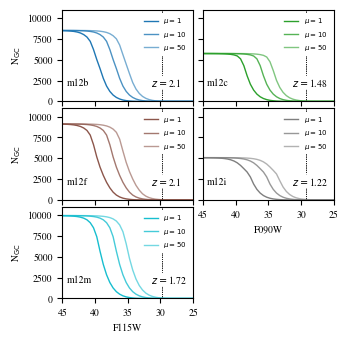

In [17]:
bins = np.arange(20, 46, 0.5)
bin_centres = 0.5 * (bins[:-1] + bins[1:])

alphas = [1.0, 0.8, 0.6, 0.4, 0.2]
# magnify_lst = [1, 2, 10, 40, 80]
magnify_lst = [1, 10, 50]

fig, axs = plt.subplots(3, 2, figsize=(3.5, 3.75))
plt.subplots_adjust(hspace=0.075, wspace=0.075)

for i, ax in enumerate(axs.flatten()):
    if i > 4:
        ax.axis("off")
        continue

    sim = sim_lst[i]
    band = get_filter(tims_dict[sim]["z"][0], redshift_bands)

    print(sim)

    for alpha, magnify in zip(alphas, magnify_lst):
        cum_count_all = np.zeros(len(bin_centres))

        detectable_counts = []
        detected_ages = []
        detected_masses = []

        n_realizations = 0

        for it_id in ssp_dict[sim]:
            if it_id == "times":
                continue

            bidx = np.where(np.array(bands) == band)[0][0]

            m_abs = ssp_dict[sim][it_id]["mags"][:, bidx]

            m_app = m_abs + cosmo.distmod(tims_dict[sim]["z"]).value - 2.5 * np.log10(magnify)

            count_per_bin, _ = np.histogram(m_app, bins=bins)
            cum_count = np.cumsum(count_per_bin)

            cum_count_all += cum_count

            det_mask = np.isfinite(m_app) & (m_app < band_limits[band])

            detectable_counts.append(np.sum(det_mask))

            if np.any(det_mask):
                ages = tims_dict[sim]["t"][0] - sim_dict[sim][it_id]["tfor"]

                masses = ssp_dict[sim][it_id]["mass"]

                detected_ages.extend(ages[det_mask])
                detected_masses.extend(masses[det_mask])

            n_realizations += 1

        cum_count_all /= n_realizations

        mean_detectable = np.mean(detectable_counts)

        if len(detected_ages) > 0:
            oldest_age = np.max(detected_ages)
            min_detect_mass = np.min(detected_masses)

            # print(
            #     f"  mu={magnify:>3}  "
            #     f"Ndet={int(round(mean_detectable)):4d}  "
            #     f"oldest={oldest_age:5.2f} Gyr  "
            #     f"log10(Mmin)={np.log10(min_detect_mass):5.2f}"
            # )

            print(
                f"  mu={magnify:>3}  "
                f"Ndet={int(round(mean_detectable)):4d}  "
                f"oldest={oldest_age:5.2f} Gyr  "
                f"Mmin={min_detect_mass / 1e5:.2f} x 10^5 Msun"
            )
        else:
            print(f"  mu={magnify:>3}  Ndet={mean_detectable:6.1f}  oldest=---  Mmin=---")

        ax.plot(
            bin_centres,
            cum_count_all,
            lw=1,
            color=sim_colors[sim],
            alpha=alpha,
            label=rf"$\mu={magnify}$",
        )

        ax.axvline(band_limits[band], ls=":", c="k", lw=0.5)

    # ax.legend(fontsize=3, loc="upper left")
    ax.legend(
        fontsize=5,
        loc="upper right",
        frameon=True,
        facecolor="white",
        edgecolor="none",
        framealpha=1.0,
    )

    ax.text(
        0.03,
        0.17,
        sim,
        transform=ax.transAxes,
        # bbox=dict(facecolor="white", edgecolor="none", boxstyle="round,pad=0.3"),
        # fontsize=5,
    )

    z_txt = r"$z = $" + str(np.round(tims_dict[sim]["z"][0], 2))
    ax.text(
        0.68,
        0.16,
        z_txt,
        transform=ax.transAxes,
        bbox=dict(facecolor="white", edgecolor="none", boxstyle="round,pad=0.1"),
        # fontsize=5,
    )

    ax.set_xlim(45, 25)
    ax.set_ylim(0, 11000)

    ax.set_yticks([0, 2500, 5000, 7500, 10000])

    if i in [0, 2, 4]:
        # ax.set_ylabel("Specific Mass Accretion (Gyr$^{-1}$)")
        ax.set_ylabel(r"N$_{\rm GC}$")
    else:
        ax.set_yticklabels([])

    if i < 3:
        ax.set_xticklabels([])
    else:
        ax.set_xlabel(f"{band.split('_')[-1].upper()}")

    print()

sa_name = "../data/figures/gc_plots/turn_off_detection.pdf"
# fig.tight_layout()
fig.savefig(sa_name, bbox_inches="tight")
plt.show()

m12b
  mu=  1  Ndet=   0.0  oldest=---  Mmin=---
  mu= 10  Ndet=   0.0  oldest=---  Mmin=---
  mu= 50  Ndet=   7  oldest= 0.76 Gyr  Mmin=5.80 x 10^5 Msun

m12c
  mu=  1  Ndet=   0.0  oldest=---  Mmin=---
  mu= 10  Ndet=   0.0  oldest=---  Mmin=---
  mu= 50  Ndet=  19  oldest= 0.71 Gyr  Mmin=5.12 x 10^5 Msun

m12f
  mu=  1  Ndet=   0.0  oldest=---  Mmin=---
  mu= 10  Ndet=   1  oldest= 0.05 Gyr  Mmin=9.25 x 10^5 Msun
  mu= 50  Ndet=  13  oldest= 0.93 Gyr  Mmin=1.84 x 10^5 Msun

m12i
  mu=  1  Ndet=   0.0  oldest=---  Mmin=---
  mu= 10  Ndet=   2  oldest= 0.20 Gyr  Mmin=13.03 x 10^5 Msun
  mu= 50  Ndet=  37  oldest= 3.22 Gyr  Mmin=2.59 x 10^5 Msun

m12m
  mu=  1  Ndet=   0.0  oldest=---  Mmin=---
  mu= 10  Ndet=   0.0  oldest=---  Mmin=---
  mu= 50  Ndet=  23  oldest= 1.54 Gyr  Mmin=7.40 x 10^5 Msun



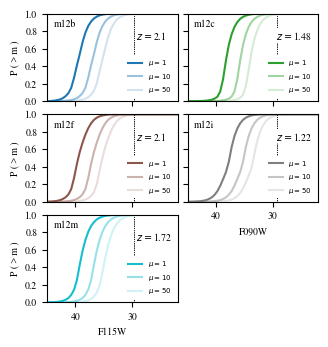

In [22]:
bins = np.arange(20, 46, 0.5)
bin_centres = 0.5 * (bins[:-1] + bins[1:])

# alphas = [1.0, 0.45, 0.2]
alphas = [1.0, 0.45, 0.2]
# magnify_lst = [1, 2, 10, 40, 80]
magnify_lst = [1, 10, 50]
# magnify_lst = [1, 10]

fig, axs = plt.subplots(3, 2, figsize=(3.5, 3.75))
plt.subplots_adjust(hspace=0.15, wspace=0.075)

for i, ax in enumerate(axs.flatten()):
    if i > 4:
        ax.axis("off")
        continue

    sim = sim_lst[i]
    band = get_filter(tims_dict[sim]["z"][0], redshift_bands)

    print(sim)

    for alpha, magnify in zip(alphas, magnify_lst):
        cum_count_all = np.zeros(len(bin_centres))

        detectable_counts = []
        detected_ages = []
        detected_masses = []

        n_realizations = 0

        for it_id in ssp_dict[sim]:
            if it_id == "times":
                continue

            bidx = np.where(np.array(bands) == band)[0][0]

            m_abs = ssp_dict[sim][it_id]["mags"][:, bidx]

            m_app = m_abs + cosmo.distmod(tims_dict[sim]["z"]).value - 2.5 * np.log10(magnify)

            count_per_bin, _ = np.histogram(m_app, bins=bins)
            cum_count = np.cumsum(count_per_bin)

            cum_count_all += cum_count

            det_mask = np.isfinite(m_app) & (m_app < band_limits[band])

            detectable_counts.append(np.sum(det_mask))

            if np.any(det_mask):
                ages = tims_dict[sim]["t"][0] - sim_dict[sim][it_id]["tfor"]

                masses = ssp_dict[sim][it_id]["mass"]

                detected_ages.extend(ages[det_mask])
                detected_masses.extend(masses[det_mask])

            n_realizations += 1

        cum_count_all /= n_realizations

        mean_detectable = np.mean(detectable_counts)

        if len(detected_ages) > 0:
            oldest_age = np.max(detected_ages)
            min_detect_mass = np.min(detected_masses)

            # print(
            #     f"  mu={magnify:>3}  "
            #     f"Ndet={int(round(mean_detectable)):4d}  "
            #     f"oldest={oldest_age:5.2f} Gyr  "
            #     f"log10(Mmin)={np.log10(min_detect_mass):5.2f}"
            # )

            print(
                f"  mu={magnify:>3}  "
                f"Ndet={int(round(mean_detectable)):4d}  "
                f"oldest={oldest_age:5.2f} Gyr  "
                f"Mmin={min_detect_mass / 1e5:.2f} x 10^5 Msun"
            )
        else:
            print(f"  mu={magnify:>3}  Ndet={mean_detectable:6.1f}  oldest=---  Mmin=---")

        ax.plot(
            bin_centres,
            1 - cum_count_all / cum_count_all[-1],
            lw=1.5,
            color=sim_colors[sim],
            alpha=alpha,
            label=rf"$\mu={magnify}$",
        )

        ax.axvline(band_limits[band], ls=":", c="k", lw=0.5)

    # ax.legend(fontsize=3, loc="upper left")
    ax.legend(
        fontsize=5,
        loc="lower right",
        frameon=True,
        facecolor="white",
        edgecolor="none",
        framealpha=1.0,
    )

    # ax.text(
    #     0.05,
    #     0.17,
    #     sim,
    #     transform=ax.transAxes,
    #     # bbox=dict(facecolor="white", edgecolor="none", boxstyle="round,pad=0.3"),
    #     # fontsize=5,
    # )

    ax.text(
        0.05,
        0.85,
        sim,
        transform=ax.transAxes,
        # bbox=dict(facecolor="white", edgecolor="none", boxstyle="round,pad=0.3"),
        # fontsize=5,
    )

    z_txt = r"$z = $" + str(np.round(tims_dict[sim]["z"][0], 2))
    # ax.text(
    #     0.68,
    #     0.16,
    #     z_txt,
    #     transform=ax.transAxes,
    #     bbox=dict(facecolor="white", edgecolor="none", boxstyle="round,pad=0.1"),
    #     # fontsize=5,
    # )

    ax.text(
        0.68,
        0.70,
        z_txt,
        transform=ax.transAxes,
        bbox=dict(facecolor="white", edgecolor="none", boxstyle="round,pad=0.1"),
        # fontsize=5,
    )

    ax.set_xlim(45, 22)
    ax.set_ylim(0, 1)

    ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])

    if i in [0, 2, 4]:
        # ax.set_ylabel("Specific Mass Accretion (Gyr$^{-1}$)")
        # ax.set_ylabel(r"N$_{\rm GC}$")
        ax.set_ylabel(r"P ( > m )")
    else:
        ax.set_yticklabels([])

    if i < 3:
        ax.set_xticklabels([])
    else:
        ax.set_xlabel(f"{band.split('_')[-1].upper()}")

    print()

sa_name = "../data/figures/gc_plots/turn_off_detection_fraction.pdf"
# fig.tight_layout()
fig.savefig(sa_name, bbox_inches="tight")
plt.show()